In [1]:
import os
import re
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from gensim.models import Word2Vec

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
print("PyTorch version:", torch.__version__)
print("Gensim version:", __import__("gensim").__version__)

Using device: cpu
PyTorch version: 2.15.0+cpu
Gensim version: 4.4.0


In [2]:
def load_tweets(filename):
    with open(filename, "r", encoding="utf-8") as file:
        return [line.rstrip("\\n") for line in file]


train_tweets = load_tweets("train_text.txt")
val_tweets = load_tweets("val_text.txt")
test_tweets = load_tweets("test_text.txt")

train_labels = np.loadtxt("train_labels.txt", dtype=int)
val_labels = np.loadtxt("val_labels.txt", dtype=int)
test_labels = np.loadtxt("test_labels.txt", dtype=int)

print("Training:", len(train_tweets), len(train_labels))
print("Validation:", len(val_tweets), len(val_labels))
print("Testing:", len(test_tweets), len(test_labels))

assert len(train_tweets) == len(train_labels)
assert len(val_tweets) == len(val_labels)
assert len(test_tweets) == len(test_labels)
assert set(np.unique(train_labels)).issubset({0, 1, 2})

print("\\nExample tweet:", train_tweets[0])
print("Example label:", train_labels[0])

Training: 45615 45615
Validation: 2000 2000
Testing: 12284 12284
\nExample tweet: "QT @user In the original draft of the 7th book, Remus Lupin survived the Battle of Hogwarts. #HappyBirthdayRemusLupin" 

Example label: 2


,Sentiment,Count
0,Negative,7093
1,Neutral,20673
2,Positive,17849


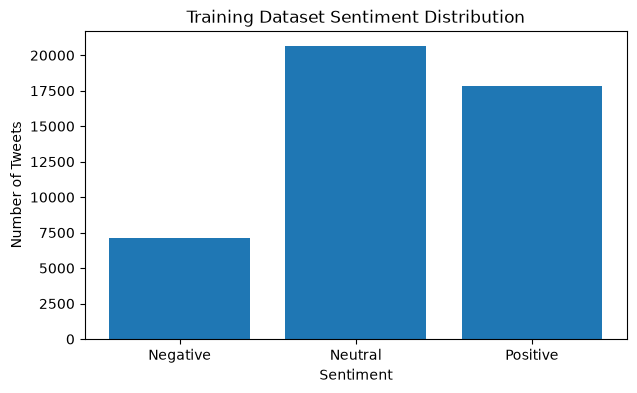

In [3]:
label_names = ["Negative", "Neutral", "Positive"]

train_distribution = pd.Series(train_labels).value_counts().sort_index()
distribution_table = pd.DataFrame({
    "Sentiment": label_names,
    "Count": [int(train_distribution.get(i, 0)) for i in range(3)]
})
display(distribution_table)

plt.figure(figsize=(7, 4))
plt.bar(distribution_table["Sentiment"], distribution_table["Count"])
plt.title("Training Dataset Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Tweets")
plt.show()

In [4]:
def tokenize_tweet(tweet):
    tweet = tweet.lower()
    tokens = re.findall(r"[a-z0-9]+(?:'[a-z]+)?", tweet)
    return tokens


example = train_tweets[0]
print("Original tweet:")
print(example)
print("\\nTokens:")
print(tokenize_tweet(example))

train_tokens = [tokenize_tweet(tweet) for tweet in train_tweets]
val_tokens = [tokenize_tweet(tweet) for tweet in val_tweets]
test_tokens = [tokenize_tweet(tweet) for tweet in test_tweets]

print("\\nTokenized training tweets:", len(train_tokens))
print("Tokenized validation tweets:", len(val_tokens))
print("Tokenized test tweets:", len(test_tokens))

Original tweet:
"QT @user In the original draft of the 7th book, Remus Lupin survived the Battle of Hogwarts. #HappyBirthdayRemusLupin" 

\nTokens:
['qt', 'user', 'in', 'the', 'original', 'draft', 'of', 'the', '7th', 'book', 'remus', 'lupin', 'survived', 'the', 'battle', 'of', 'hogwarts', 'happybirthdayremuslupin']
\nTokenized training tweets: 45615
Tokenized validation tweets: 2000
Tokenized test tweets: 12284


In [5]:
EMBEDDING_DIM = 100
WORD2VEC_WINDOW = 5
WORD2VEC_MIN_COUNT = 2
WORD2VEC_EPOCHS = 10

def train_word2vec(tokenized_tweets, seed=SEED):
    # Word2Vec requires a list of token lists.
    model = Word2Vec(
        sentences=tokenized_tweets,
        vector_size=EMBEDDING_DIM,
        window=WORD2VEC_WINDOW,
        min_count=WORD2VEC_MIN_COUNT,
        workers=4,
        sg=1,              # Skip-gram
        negative=5,
        epochs=WORD2VEC_EPOCHS,
        seed=seed
    )
    return model


word2vec_model = train_word2vec(train_tokens)

print("Word2Vec vocabulary size:", len(word2vec_model.wv))
print("Embedding dimension:", word2vec_model.vector_size)

Word2Vec vocabulary size: 19928
Embedding dimension: 100


In [6]:
PAD_TOKEN = "<PAD>"
UNK_TOKEN = "<UNK>"
PAD_IDX = 0
UNK_IDX = 1

def build_vocabulary_and_embeddings(w2v_model):
    word_to_idx = {
        PAD_TOKEN: PAD_IDX,
        UNK_TOKEN: UNK_IDX
    }

    for word in w2v_model.wv.index_to_key:
        if word not in word_to_idx:
            word_to_idx[word] = len(word_to_idx)

    embedding_matrix = np.zeros(
        (len(word_to_idx), EMBEDDING_DIM),
        dtype=np.float32
    )

    # Initialize the unknown token vector.
    rng = np.random.default_rng(SEED)
    embedding_matrix[UNK_IDX] = rng.normal(
        0, 0.1, EMBEDDING_DIM
    ).astype(np.float32)

    for word, index in word_to_idx.items():
        if word in (PAD_TOKEN, UNK_TOKEN):
            continue
        embedding_matrix[index] = w2v_model.wv[word]

    return word_to_idx, torch.tensor(embedding_matrix, dtype=torch.float32)


word_to_idx, embedding_weights = build_vocabulary_and_embeddings(word2vec_model)

print("Vocabulary size:", len(word_to_idx))
print("Embedding matrix shape:", tuple(embedding_weights.shape))

Vocabulary size: 19930
Embedding matrix shape: (19930, 100)


In [7]:
MAX_LEN = 50

def encode_tweet(tokens, vocabulary, max_len=MAX_LEN):
    token_ids = [
        vocabulary.get(token, UNK_IDX)
        for token in tokens
    ]

    # Truncate long tweets.
    token_ids = token_ids[:max_len]

    # Pad short tweets.
    if len(token_ids) < max_len:
        token_ids += [PAD_IDX] * (max_len - len(token_ids))

    return token_ids


def encode_tweets(tokenized_tweets, vocabulary, max_len=MAX_LEN):
    encoded = [
        encode_tweet(tokens, vocabulary, max_len)
        for tokens in tokenized_tweets
    ]
    return torch.tensor(encoded, dtype=torch.long)


X_train = encode_tweets(train_tokens, word_to_idx)
X_val = encode_tweets(val_tokens, word_to_idx)
X_test = encode_tweets(test_tokens, word_to_idx)

y_train = torch.tensor(train_labels, dtype=torch.long)
y_val = torch.tensor(val_labels, dtype=torch.long)
y_test = torch.tensor(test_labels, dtype=torch.long)

print("Training tensor:", tuple(X_train.shape))
print("Validation tensor:", tuple(X_val.shape))
print("Testing tensor:", tuple(X_test.shape))

Training tensor: (45615, 50)
Validation tensor: (2000, 50)
Testing tensor: (12284, 50)


In [8]:
class TweetDataset(Dataset):
    def __init__(self, sequences, labels):
        self.sequences = sequences
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        return self.sequences[index], self.labels[index]


train_dataset = TweetDataset(X_train, y_train)
val_dataset = TweetDataset(X_val, y_val)
test_dataset = TweetDataset(X_test, y_test)

print("Training dataset size:", len(train_dataset))
print("One sequence shape:", train_dataset[0][0].shape)
print("One label:", train_dataset[0][1].item())

Training dataset size: 45615
One sequence shape: torch.Size([50])
One label: 2


In [9]:
BATCH_SIZE = 128

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

sample_sequences, sample_labels = next(iter(train_loader))
print("Batch sequence shape:", tuple(sample_sequences.shape))
print("Batch label shape:", tuple(sample_labels.shape))

Batch sequence shape: (128, 50)
Batch label shape: (128,)


In [10]:
class SentimentClassifier(nn.Module):
    def __init__(self, embedding_matrix, hidden_dim=128, freeze_embeddings=True):
        super().__init__()

        self.embedding = nn.Embedding.from_pretrained(
            embedding_matrix,
            freeze=freeze_embeddings,
            padding_idx=PAD_IDX
        )

        self.fc1 = nn.Linear(EMBEDDING_DIM, hidden_dim)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_dim, 3)

        self.softmax = nn.Softmax(dim=1)

    def forward(self, input_ids):
        # Shape: (batch_size, sequence_length, embedding_dim)
        embedded = self.embedding(input_ids)

        # Ignore padding positions when calculating the tweet representation.
        mask = (input_ids != PAD_IDX).unsqueeze(-1).float()
        summed_embeddings = (embedded * mask).sum(dim=1)
        token_counts = mask.sum(dim=1).clamp(min=1.0)
        tweet_vectors = summed_embeddings / token_counts

        hidden = self.relu(self.fc1(tweet_vectors))
        logits = self.fc2(hidden)

        return logits

    def predict_proba(self, input_ids):
        logits = self.forward(input_ids)
        return self.softmax(logits)


model = SentimentClassifier(
    embedding_weights,
    hidden_dim=128,
    freeze_embeddings=True
).to(device)

print(model)
print("Embedding weights frozen:", not model.embedding.weight.requires_grad)

SentimentClassifier(
  (embedding): Embedding(19930, 100, padding_idx=0)
  (fc1): Linear(in_features=100, out_features=128, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=128, out_features=3, bias=True)
  (softmax): Softmax(dim=1)
)
Embedding weights frozen: True


In [11]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    filter(lambda parameter: parameter.requires_grad, model.parameters()),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)

Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [12]:
def evaluate_model(model, data_loader):
    model.eval()
    all_predictions = []
    all_labels = []

    with torch.no_grad():
        for sequences, labels in data_loader:
            sequences = sequences.to(device)
            labels = labels.to(device)

            logits = model(sequences)
            predictions = torch.argmax(logits, dim=1)

            all_predictions.extend(predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    accuracy = accuracy_score(all_labels, all_predictions)
    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    return accuracy, macro_f1, all_labels, all_predictions


def train_model(model, train_loader, validation_loader, epochs=8, learning_rate=0.001):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(
        filter(lambda parameter: parameter.requires_grad, model.parameters()),
        lr=learning_rate
    )

    history = {
        "train_loss": [],
        "val_accuracy": [],
        "val_macro_f1": []
    }

    for epoch in range(epochs):
        model.train()
        total_loss = 0.0

        for sequences, labels in train_loader:
            sequences = sequences.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            logits = model(sequences)
            loss = criterion(logits, labels)

            # Autodiff: calculate gradients.
            loss.backward()

            # Adam: update trainable parameters.
            optimizer.step()

            total_loss += loss.item()

        average_loss = total_loss / len(train_loader)
        val_accuracy, val_macro_f1, _, _ = evaluate_model(
            model, validation_loader
        )

        history["train_loss"].append(average_loss)
        history["val_accuracy"].append(val_accuracy)
        history["val_macro_f1"].append(val_macro_f1)

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Loss: {average_loss:.4f} | "
            f"Validation Accuracy: {val_accuracy:.4f} | "
            f"Validation Macro F1: {val_macro_f1:.4f}"
        )

    return history

In [13]:
EPOCHS = 8

history = train_model(
    model,
    train_loader,
    val_loader,
    epochs=EPOCHS,
    learning_rate=0.001
)

Epoch 1/8 | Loss: 0.9106 | Validation Accuracy: 0.5625 | Validation Macro F1: 0.4773
Epoch 2/8 | Loss: 0.8501 | Validation Accuracy: 0.5685 | Validation Macro F1: 0.5090
Epoch 3/8 | Loss: 0.8385 | Validation Accuracy: 0.5725 | Validation Macro F1: 0.4846
Epoch 4/8 | Loss: 0.8314 | Validation Accuracy: 0.5870 | Validation Macro F1: 0.5060
Epoch 5/8 | Loss: 0.8258 | Validation Accuracy: 0.5925 | Validation Macro F1: 0.5379
Epoch 6/8 | Loss: 0.8217 | Validation Accuracy: 0.5955 | Validation Macro F1: 0.5418
Epoch 7/8 | Loss: 0.8180 | Validation Accuracy: 0.5970 | Validation Macro F1: 0.5490
Epoch 8/8 | Loss: 0.8141 | Validation Accuracy: 0.5905 | Validation Macro F1: 0.5337


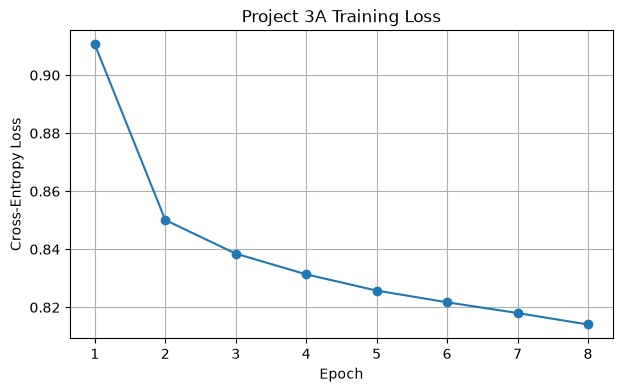

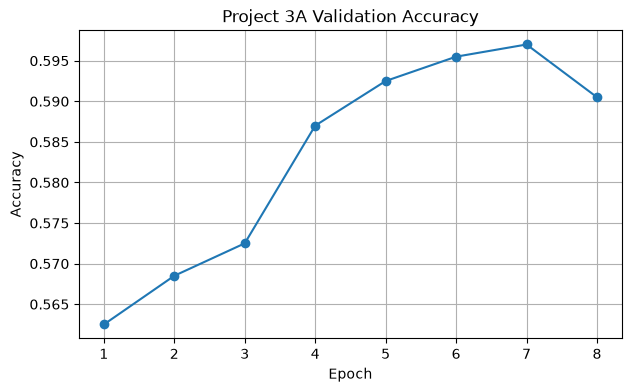

In [14]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, EPOCHS + 1), history["train_loss"], marker="o")
plt.title("Project 3A Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.grid(True)
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(range(1, EPOCHS + 1), history["val_accuracy"], marker="o")
plt.title("Project 3A Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.grid(True)
plt.show()

In [15]:
def make_fold_tensors(token_lists, labels, vocabulary, max_len=MAX_LEN):
    sequences = encode_tweets(token_lists, vocabulary, max_len)
    targets = torch.tensor(labels, dtype=torch.long)
    return sequences, targets


def run_cross_validation(raw_tweets, labels, n_splits=5, epochs=3):
    labels_array = np.asarray(labels)
    splitter = StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=SEED
    )

    fold_results = []

    for fold_number, (train_indices, val_indices) in enumerate(
        splitter.split(np.zeros(len(labels_array)), labels_array), start=1
    ):
        print(f"\\n========== Fold {fold_number}/{n_splits} ==========")

        fold_train_tokens = [train_tokens[i] for i in train_indices]
        fold_val_tokens = [train_tokens[i] for i in val_indices]

        fold_train_labels = labels_array[train_indices]
        fold_val_labels = labels_array[val_indices]

        # Train Word2Vec only on this fold's training tweets.
        fold_w2v = train_word2vec(fold_train_tokens, seed=SEED + fold_number)
        fold_vocab, fold_embeddings = build_vocabulary_and_embeddings(fold_w2v)

        fold_X_train, fold_y_train = make_fold_tensors(
            fold_train_tokens, fold_train_labels, fold_vocab
        )
        fold_X_val, fold_y_val = make_fold_tensors(
            fold_val_tokens, fold_val_labels, fold_vocab
        )

        fold_train_dataset = TweetDataset(fold_X_train, fold_y_train)
        fold_val_dataset = TweetDataset(fold_X_val, fold_y_val)

        fold_train_loader = DataLoader(
            fold_train_dataset,
            batch_size=BATCH_SIZE,
            shuffle=True
        )
        fold_val_loader = DataLoader(
            fold_val_dataset,
            batch_size=BATCH_SIZE,
            shuffle=False
        )

        fold_model = SentimentClassifier(
            fold_embeddings,
            hidden_dim=128,
            freeze_embeddings=True
        ).to(device)

        fold_history = train_model(
            fold_model,
            fold_train_loader,
            fold_val_loader,
            epochs=epochs,
            learning_rate=0.001
        )

        fold_accuracy, fold_macro_f1, _, _ = evaluate_model(
            fold_model, fold_val_loader
        )

        fold_results.append({
            "Fold": fold_number,
            "Accuracy": fold_accuracy,
            "Macro F1": fold_macro_f1
        })

        print(
            f"Fold {fold_number} result: "
            f"Accuracy={fold_accuracy:.4f}, "
            f"Macro F1={fold_macro_f1:.4f}"
        )

    return pd.DataFrame(fold_results)


# Set epochs=3 for a manageable first run. Increase if your instructor expects
# more training per fold or if you have sufficient time and computing resources.
cv_results = run_cross_validation(
    train_tweets,
    train_labels,
    n_splits=5,
    epochs=3
)

display(cv_results)
print("\\nMean cross-validation accuracy:", cv_results["Accuracy"].mean())
print("Mean cross-validation macro F1:", cv_results["Macro F1"].mean())

\n========== Fold 1/5 ==========
Epoch 1/3 | Loss: 0.9283 | Validation Accuracy: 0.5681 | Validation Macro F1: 0.4767
Epoch 2/3 | Loss: 0.8681 | Validation Accuracy: 0.5830 | Validation Macro F1: 0.4877
Epoch 3/3 | Loss: 0.8522 | Validation Accuracy: 0.5902 | Validation Macro F1: 0.5157
Fold 1 result: Accuracy=0.5902, Macro F1=0.5157
\n========== Fold 2/5 ==========
Epoch 1/3 | Loss: 0.9257 | Validation Accuracy: 0.5785 | Validation Macro F1: 0.5002
Epoch 2/3 | Loss: 0.8658 | Validation Accuracy: 0.5915 | Validation Macro F1: 0.4983
Epoch 3/3 | Loss: 0.8542 | Validation Accuracy: 0.5985 | Validation Macro F1: 0.5053
Fold 2 result: Accuracy=0.5985, Macro F1=0.5053
\n========== Fold 3/5 ==========
Epoch 1/3 | Loss: 0.9285 | Validation Accuracy: 0.5706 | Validation Macro F1: 0.4516
Epoch 2/3 | Loss: 0.8592 | Validation Accuracy: 0.5782 | Validation Macro F1: 0.4699
Epoch 3/3 | Loss: 0.8480 | Validation Accuracy: 0.5778 | Validation Macro F1: 0.4598
Fold 3 result: Accuracy=0.5778, Macro F1

,Fold,Accuracy,Macro F1
0,1,0.590157,0.515738
1,2,0.598487,0.505300
2,3,0.577770,0.459795
3,4,0.584238,0.495153
4,5,0.588622,0.496497


\nMean cross-validation accuracy: 0.5878548723007783
Mean cross-validation macro F1: 0.49449670572444093


In [16]:
test_accuracy, test_macro_f1, true_labels, predicted_labels = evaluate_model(
    model, test_loader
)

print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Macro F1: {test_macro_f1:.4f}")

print("\\nClassification Report:")
print(classification_report(
    true_labels,
    predicted_labels,
    labels=[0, 1, 2],
    target_names=label_names,
    digits=4,
    zero_division=0
))

Test Accuracy: 0.5680
Test Macro F1: 0.5358
\nClassification Report:
              precision    recall  f1-score   support

    Negative     0.5811    0.3691    0.4514      3972
     Neutral     0.5714    0.7322    0.6419      5937
    Positive     0.5404    0.4901    0.5140      2375

    accuracy                         0.5680     12284
   macro avg     0.5643    0.5305    0.5358     12284
weighted avg     0.5685    0.5680    0.5556     12284



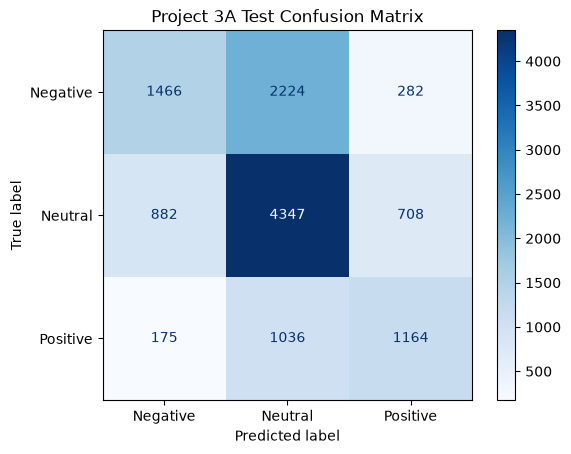

In [17]:
cm = confusion_matrix(true_labels, predicted_labels, labels=[0, 1, 2])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_names
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Project 3A Test Confusion Matrix")
plt.show()

In [18]:
os.makedirs("project3a_outputs", exist_ok=True)

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "embedding_weights": embedding_weights,
        "word_to_idx": word_to_idx,
        "embedding_dim": EMBEDDING_DIM,
        "max_len": MAX_LEN,
        "label_names": label_names
    },
    "project3a_outputs/project3a_frozen_model.pt"
)

cv_results.to_csv(
    "project3a_outputs/project3a_cross_validation.csv",
    index=False
)

print("Saved Project 3A model and cross-validation results.")

Saved Project 3A model and cross-validation results.
